# МОМО: лабораторная № 1

## Численные методы линейной алгебры в задаче наименьших квадратов

# 1.1 Цель работы

Исследовать влияние ранга и обусловленности матрицы данных на численное решение задачи наи-
меньших квадратов; сопоставить прямой, итерационный и спектральный способы решения; изучить
действие сокращения размерности и регуляризации.
Работа строится как единый вычислительный эксперимент. Все сравниваемые методы используют
одно разбиение данных и согласованный способ подготовки признаков.

# 1.2 Исходные данные

## Superconductors: предсказание критической температуры

**Задача регрессии:** по числовым характеристикам химического состава материала предсказать его критическую температуру `critical_temp` в кельвинах (К). При охлаждении ниже этой температуры материал переходит в сверхпроводящее состояние. Данные содержат сведения об известных сверхпроводниках.

Одна строка — запись о материале. Файл `train.csv` содержит полный набор: **21 263 наблюдения, 81 входной признак и 1 целевой столбец**, пропуски отсутствуют по описанию UCI. В экспериментах используются **8 вещественных признаков**: средние арифметические каждого из восьми свойств элементов (`mean_...`). Эти столбцы уже рассчитаны автором; новые признаки в этом ноутбуке не создаются.

| Переменная | Роль | Тип | Смысл |
|---|---|---|---|
| `critical_temp` | Целевая переменная `y` | Вещественная | Экспериментальная критическая температура, К |
| Выбранные 8 столбцов `mean_...` | Признаки `X` | Вещественные | Средние арифметические свойств различных элементов в составе |

Целевой столбец исключается из `X` и не используется при вычислении исходных признаков: они получены из состава и свойств элементов, а температура — из экспериментальных данных.

**Источники:** [Kaggle: Superconductors](https://www.kaggle.com/datasets/anlgrbz/super-conductors), [UCI: Superconductivty Data](https://archive.ics.uci.edu/dataset/464/superconductivty+data). Автор подготовленного набора — Kam Hamidieh; исходные сведения собраны из NIMS SuperCon. Очистка и расчёт признаков описаны в [статье автора, раздел 2](https://arxiv.org/html/1803.10260).

## Восемь выбранных признаков

Для каждого свойства **химических элементов, входящих в материал**, оставляем только среднее арифметическое. Это готовые агрегаты по различным элементам состава, без учёта их долей. Например, `mean_Density` — среднее плотностей элементов, а не прямое измерение плотности самого материала.

| Используемый столбец | Свойство элемента | Единицы исходного свойства | Смысл |
|---|---|---|---|
| `mean_atomic_mass` | Атомная масса | а.е.м. | Масса атома |
| `mean_fie` | Энергия первой ионизации | кДж/моль | Энергия удаления первого электрона |
| `mean_atomic_radius` | Атомный радиус | пм | Размер атома |
| `mean_Density` | Плотность | кг/м³ | Масса на единицу объёма при стандартных условиях |
| `mean_ElectronAffinity` | Сродство к электрону | кДж/моль | Энергетическая характеристика присоединения электрона |
| `mean_FusionHeat` | Теплота плавления | кДж/моль | Энергия перехода из твёрдого состояния в жидкое |
| `mean_ThermalConductivity` | Теплопроводность | Вт/(м·К) | Способность проводить тепло |
| `mean_Valence` | Валентность | Безразмерная | Типичное число образуемых химических связей |

Единицы указаны для базовых свойств. Энтропия — безразмерная производная характеристика. При подготовке исходного набора автор добавил 1,5 к значениям сродства к электрону для корректного расчёта логарифмов. [Описание базовых свойств](https://arxiv.org/html/1803.10260#S2.SS1).


## Характеристики исходного набора и выбор признаков

Для каждого из восьми свойств уже рассчитаны следующие десять характеристик. Взвешенные версии учитывают доли элементов в химической формуле. Подробные определения, включая специальные формулы взвешенной энтропии и размаха, приведены в [разделе 2.3 статьи](https://arxiv.org/html/1803.10260#S2.SS3).

| Префикс | Характеристика | Что описывает | Пример столбца |
|---|---|---|---|
| `mean_` | Среднее арифметическое | Средний уровень свойства по различным элементам | `mean_atomic_mass` |
| `wtd_mean_` | Взвешенное среднее | Средний уровень с учётом долей элементов | `wtd_mean_atomic_mass` |
| `gmean_` | Среднее геометрическое | Мультипликативное усреднение значений | `gmean_atomic_mass` |
| `wtd_gmean_` | Взвешенное геометрическое среднее | Геометрическое усреднение с учётом долей | `wtd_gmean_atomic_mass` |
| `entropy_` | Энтропия | Равномерность нормированных значений свойства | `entropy_atomic_mass` |
| `wtd_entropy_` | Взвешенная энтропия | Равномерность с учётом долей элементов | `wtd_entropy_atomic_mass` |
| `range_` | Размах | Разность максимального и минимального значений | `range_atomic_mass` |
| `wtd_range_` | Взвешенный размах | Размах значений после умножения на доли элементов | `wtd_range_atomic_mass` |
| `std_` | Стандартное отклонение | Разброс значений вокруг среднего | `std_atomic_mass` |
| `wtd_std_` | Взвешенное стандартное отклонение | Разброс с учётом долей элементов | `wtd_std_atomic_mass` |

В исходном CSV: 8 свойств × 10 характеристик + `number_of_elements` = **81 признак**. Для этой работы из них выбираются **только 8 столбцов `mean_...`**, перечисленных выше. Другие агрегаты и `number_of_elements` в матрицу `X` не включаются. Выбор фиксирован до разбиения и не зависит от целевой переменной.


Оставим только базовые признаки среднего для упрощения

# 1.3 Постановка задачи

Для обучающей матрицы $X \in \mathbb{R}^{n \times p}$ и вектора ответов $y \in \mathbb{R}^{n}$ рассматривается задача:

$$
\min_{\beta \in \mathbb{R}^{p}} \|X\beta - y\|_2^2.
$$

Соответствующие нормальные уравнения:

$$
A\beta = b, \qquad A = X^{T}X, \qquad b = X^{T}y.
$$

Основной показатель качества прогноза — **RMSE на тестовой части**:

$$
\operatorname{RMSE}
=
\sqrt{\frac{1}{n_{\text{test}}}
\sum_{i=1}^{n_{\text{test}}}(y_i - \hat{y}_i)^2}.
$$

# 1.4 Обязательная часть

## Установка зависимостей, загрузка датасета и деление данных

Запускайте ячейки сверху вниз в Jupyter, VS Code, Google Colab или Kaggle. Требуется **Python 3.10+** и доступ в интернет. Команда `%pip` устанавливает библиотеки в окружение текущего ядра.

In [2]:
%pip install -q "kagglehub>=1.0.3" pandas numpy "scikit-learn>=1.2" matplotlib



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
from IPython.display import display

DATASET_HANDLE = "anlgrbz/super-conductors/versions/1"
CSV_NAME = "train.csv"

csv_path = Path(kagglehub.dataset_download(DATASET_HANDLE, path=CSV_NAME))
print(f"CSV загружен: {csv_path}")


/Users/aleksandr/Documents/GitReps/MOMO_labs/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CSV загружен: /Users/aleksandr/.cache/kagglehub/datasets/anlgrbz/super-conductors/versions/1/train.csv


In [4]:
df = pd.read_csv(csv_path)

print(f"Наблюдений: {df.shape[0]:,}")
print(f"Столбцов: {df.shape[1]}")
display(df.head())


Наблюдений: 21,263
Столбцов: 82


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


In [5]:
TARGET = "critical_temp"

assert TARGET in df.columns, f"В CSV отсутствует целевой столбец {TARGET!r}."
assert df.shape == (21263, 82), f"Неожиданный размер таблицы: {df.shape}"
assert df.select_dtypes(include="number").shape[1] == df.shape[1], "Есть нечисловые столбцы."
assert not df.isna().any().any(), "В данных обнаружены пропуски."

print(f"Признаков в исходном CSV: {df.shape[1] - 1}")
print(f"Пропусков: {int(df.isna().sum().sum())}")
print(f"Целевая переменная: {TARGET}")


Признаков в исходном CSV: 81
Пропусков: 0
Целевая переменная: critical_temp


In [6]:
SEED = 42
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15

FEATURES = [
    "mean_atomic_mass",
    "mean_fie",
    "mean_atomic_radius",
    "mean_Density",
    "mean_ElectronAffinity",
    "mean_FusionHeat",
    "mean_ThermalConductivity",
    "mean_Valence",
]

X = df[FEATURES].copy()
y = df[TARGET]

rng = np.random.default_rng(SEED)
shuffled_indices = rng.permutation(df.index.to_numpy())
n_train = int(len(df) * TRAIN_FRACTION)
n_val = int(len(df) * VAL_FRACTION)

train_indices = shuffled_indices[:n_train]
val_indices = shuffled_indices[n_train:n_train + n_val]
test_indices = shuffled_indices[n_train + n_val:]

X_train, X_val, X_test = (X.loc[idx].copy() for idx in (train_indices, val_indices, test_indices))
y_train, y_val, y_test = (y.loc[idx].copy() for idx in (train_indices, val_indices, test_indices))


In [7]:
assert df.index.is_unique, "Для разбиения нужны уникальные индексы строк."
assert np.isclose(TRAIN_FRACTION + VAL_FRACTION + TEST_FRACTION, 1.0)
assert len(X_train) + len(X_val) + len(X_test) == len(df)
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty
assert set(X_train.index) | set(X_val.index) | set(X_test.index) == set(df.index)

for features, target in ((X_train, y_train), (X_val, y_val), (X_test, y_test)):
    assert features.index.equals(target.index), "Индексы признаков и цели не совпадают."
    assert TARGET not in features.columns, "Целевой столбец попал в признаки."

split_summary = pd.DataFrame({
    "Подвыборка": ["train", "val", "test"],
    "Наблюдений": [len(X_train), len(X_val), len(X_test)],
    "Признаков": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
})
split_summary["Доля, %"] = (split_summary["Наблюдений"] / len(df) * 100).round(2)

print(f"Seed: {SEED}")
display(split_summary)


Seed: 42


,Подвыборка,Наблюдений,Признаков,"Доля, %"
0,train,14884,8,70.0
1,val,3189,8,15.0
2,test,3190,8,15.0


Определим матрицы A и b для трейновой части

In [8]:
A_train = X_train.T @ X_train
b_train = X_train.T @ y_train

## 1.4.1 Исследование матрицы данных

Для исходной и стандартизованной матриц используем SVD и одно правило численного ранга:

$$
\tau = \sigma_{\max}\max(n,p)\varepsilon_{\mathrm{mach}},
\qquad r_{\mathrm{num}} = \#\{i:\sigma_i>\tau\}.
$$

Фактический допуск вычисляется отдельно для каждой матрицы. Число обусловленности в норме 2 определяется отношением максимального сингулярного числа к минимальному. При полном столбцовом ранге в точной арифметике $\kappa_2(X^TX)=\kappa_2(X)^2$

In [9]:
from sklearn.preprocessing import StandardScaler

In [10]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)

In [11]:
eigenvalues = np.linalg.eigvalsh(A_train)

singular_values = np.linalg.svd(X_train, compute_uv=False)
singular_values_std = np.linalg.svd(X_train_std, compute_uv=False)

tol = singular_values[0] * max(X_train.shape) * np.finfo(singular_values.dtype).eps
tol_std = singular_values_std[0] * max(X_train_std.shape) * np.finfo(singular_values_std.dtype).eps

rank = np.count_nonzero(singular_values > tol)
rank_std = np.count_nonzero(singular_values_std > tol_std)

A_train_std = X_train_std.T @ X_train_std
eigenvalues_std = np.linalg.eigvalsh(A_train_std)

cond_X_train = singular_values[0] / singular_values[-1] if singular_values[-1] > 0 else np.inf
cond_X_train_std = singular_values_std[0] / singular_values_std[-1] if singular_values_std[-1] > 0 else np.inf

cond_A_train = cond_X_train ** 2
cond_A_train_std = cond_X_train_std ** 2

cond_A_train_eig = eigenvalues[-1] / eigenvalues[0] if eigenvalues[0] > tol else np.inf
cond_A_train_std_eig = eigenvalues_std[-1] / eigenvalues_std[0] if eigenvalues_std[0] > tol_std else np.inf

relative_difference_A_train = abs(cond_A_train_eig - cond_A_train) / cond_A_train if np.isfinite(cond_A_train_eig) and np.isfinite(cond_A_train) else np.nan
relative_difference_A_train_std = abs(cond_A_train_std_eig - cond_A_train_std) / cond_A_train_std if np.isfinite(cond_A_train_std_eig) and np.isfinite(cond_A_train_std) else np.nan

matrix_diagnostics = pd.DataFrame({
    "Матрица": ["До стандартизации", "После стандартизации"],
    "Наблюдений": [X_train.shape[0], X_train_std.shape[0]],
    "Признаков": [X_train.shape[1], X_train_std.shape[1]],
    "Допуск": [tol, tol_std],
    "Численный ранг": [rank, rank_std],
    "κ₂(X)": [cond_X_train, cond_X_train_std],
    "κ₂(XᵀX)": [cond_A_train, cond_A_train_std],
    "λ_max / λ_min": [cond_A_train_eig, cond_A_train_std_eig],
    "Относительное различие": [relative_difference_A_train, relative_difference_A_train_std],
})

with pd.option_context("display.float_format", "{:.6e}".format, "display.max_columns", None):
    display(matrix_diagnostics)


,Матрица,Наблюдений,Признаков,Допуск,Численный ранг,κ₂(X),κ₂(XᵀX),λ_max / λ_min,Относительное различие
0,До стандартизации,14884,8,2.735261e-06,8,1.250998e+04,1.564997e+08,1.564997e+08,1.504401e-14
1,После стандартизации,14884,8,6.677926e-10,8,6.654204e+00,4.427844e+01,4.427844e+01,6.900275e-15


In [12]:
singular_values

array([8.27635041e+05, 4.36047741e+04, 5.09628796e+03, 3.84319338e+03,
       2.83412720e+03, 1.96460106e+03, 1.05473149e+03, 6.61579591e+01])

Обе матрицы имеют численный ранг равный количеству признаков при заданном допуске, что говорит о том, что коллинеарных признаков нет. Число обусловленности kappa_2(X) и kappa_2(X^T@X) уменьшается после стандартизации X, так как стандартизация центрировала признаки и привела их к сопоставимому масштабу и в результате матрица стала более равномерно растягивать разные направления

### Сингулярные числа


In [13]:
singular_values_table = pd.DataFrame({
    "Номер": np.arange(1, len(singular_values) + 1),
    "До стандартизации": singular_values,
    "После стандартизации": singular_values_std,
})

with pd.option_context("display.max_rows", None):
    display(singular_values_table)


,Номер,До стандартизации,После стандартизации
0,1,827635.041276,202.060640
1,2,43604.774072,176.373633
2,3,5096.287955,129.671406
3,4,3843.193378,121.163314
4,5,2834.127196,83.259186
5,6,1964.601062,67.083801
6,7,1054.731490,57.325417
7,8,66.157959,30.365860


Также стандартизация уменьшила абсолютные значения сингулярных значений, так как стандарттзация уменьшила масштаб признаков

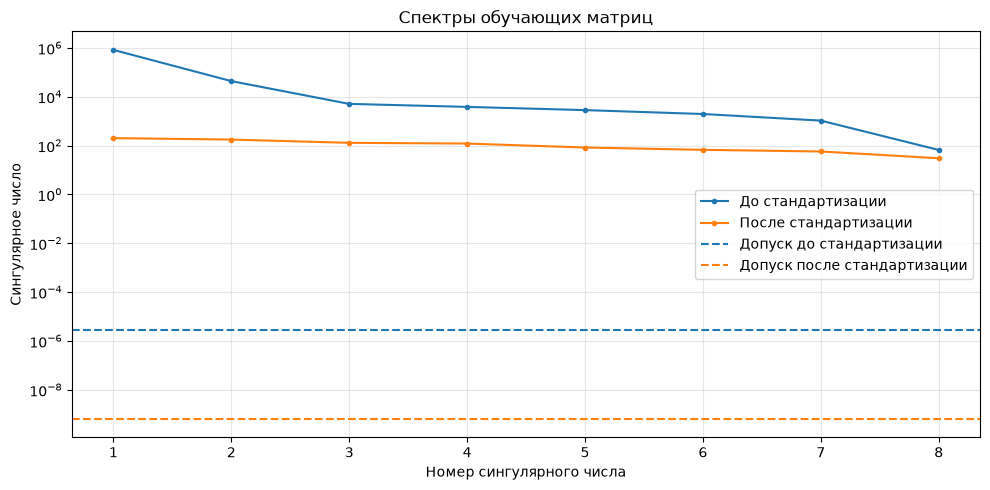

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(singular_values_table["Номер"], singular_values, "o-", markersize=3, label="До стандартизации")
ax.semilogy(singular_values_table["Номер"], singular_values_std, "o-", markersize=3, label="После стандартизации")
ax.axhline(tol, color="tab:blue", linestyle="--", label="Допуск до стандартизации")
ax.axhline(tol_std, color="tab:orange", linestyle="--", label="Допуск после стандартизации")
ax.set(xlabel="Номер сингулярного числа", ylabel="Сингулярное число", title="Спектры обучающих матриц")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


ИЗ графика видно, что после стандартизации сингулярные числа стали примерно одного порядка и разброс уменьшился, так как сингулярные направления матрицы X были отмасштиброваны и влияние в разницах масштаба уменьшилось

### Корреляционные матрицы количественных признаков

Корреляции Пирсона рассчитываются по обучающей части для 8 выбранных признаков. Положительное масштабирование и центрирование сохраняют корреляции, поэтому матрицы до и после StandardScaler должны совпадать с точностью до округления.


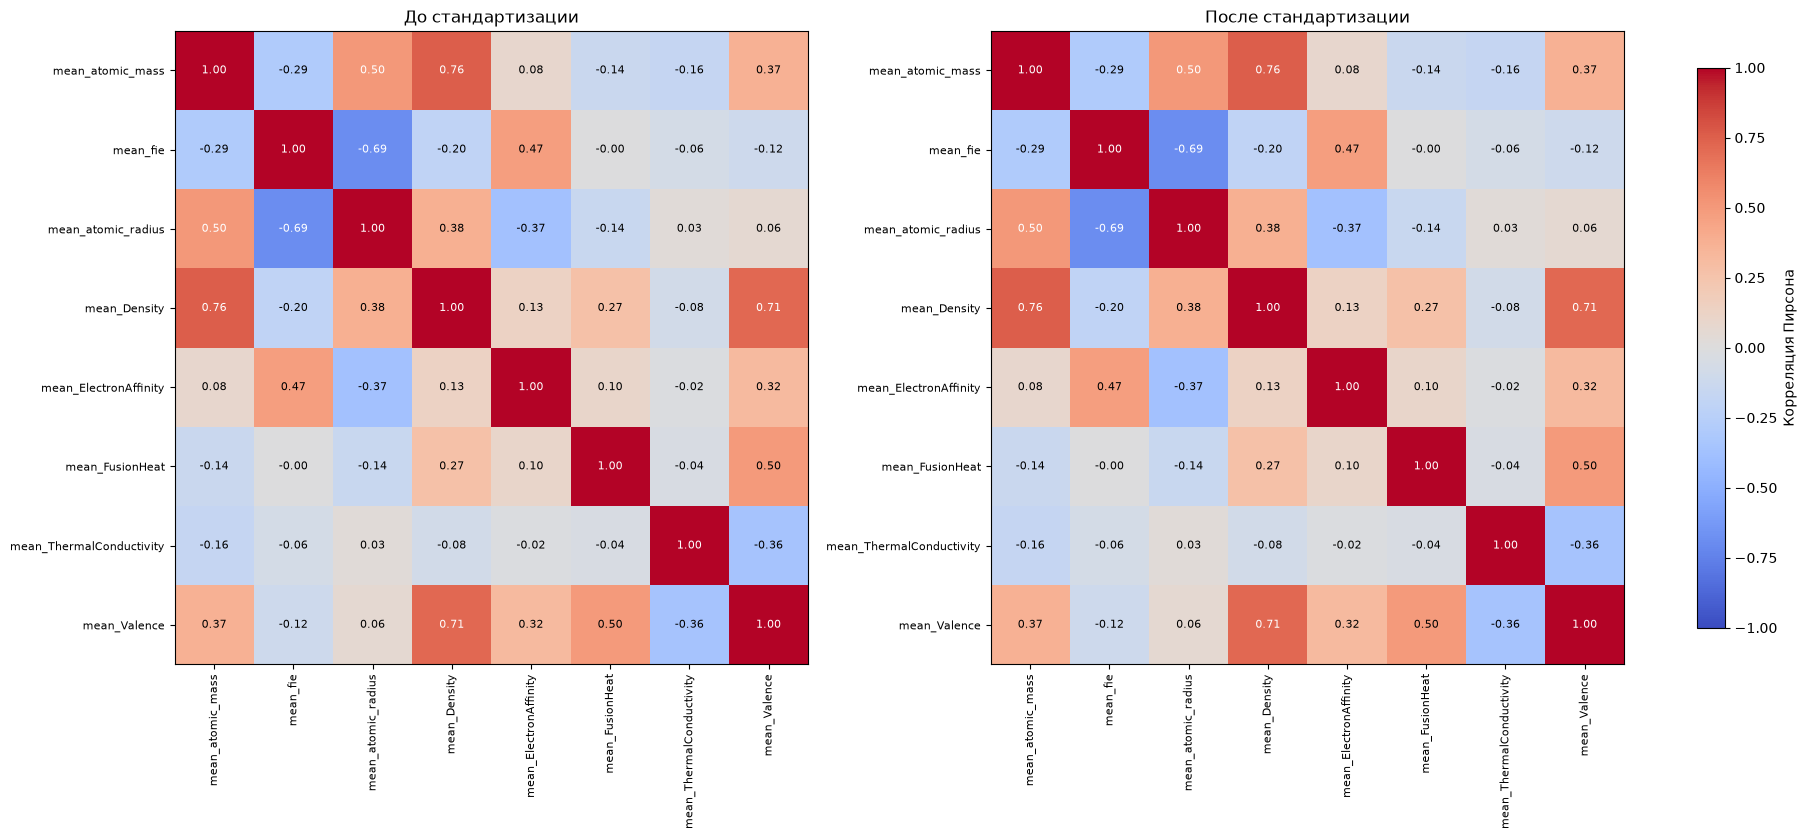

Максимальное различие корреляций: 7.549516567451064e-15


In [15]:
X_train_std_df = pd.DataFrame(X_train_std, index=X_train.index, columns=X_train.columns)

corr_train = X_train.corr(method="pearson")
corr_train_std = X_train_std_df.corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(18, 9), layout="constrained")
for ax, corr, title in zip(
    axes,
    (corr_train, corr_train_std),
    ("До стандартизации", "После стандартизации"),
):
    image = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
    ticks = np.arange(len(corr.columns))
    ax.set_xticks(ticks, labels=corr.columns, rotation=90, fontsize=8)
    ax.set_yticks(ticks, labels=corr.index, fontsize=8)
    ax.set_title(title)
    for row in range(len(corr)):
        for col in range(len(corr.columns)):
            value = corr.iloc[row, col]
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.5 else "black")

fig.colorbar(image, ax=axes, shrink=0.7, label="Корреляция Пирсона")
plt.show()

print("Максимальное различие корреляций:", np.max(np.abs(corr_train.to_numpy() - corr_train_std.to_numpy())))


Корреляции до и после стандартизации не отличаются, так как стандартизация не меняет линейную зависимость между признаками. Прямой линейной зависимости между признаками нет.

### Вывод об обусловленности и мультиколлинеарности

Численный ранг до и после стандартизации матрицы равен 8, то есть полному рангу. Использованы вычисленные допуски 2,74·10⁻⁶ и 6,68·10⁻¹⁰ соответственно. Прямой линейной зваисимости между признаками не выявлено.

До стандартизации число обусловленности **κ₂(X) ≈ 1,25·10⁴**, а для матрицы нормальных уравнений **κ₂(XᵀX) ≈ 1,56·10⁸**. После стандартизации эти значения снижаются до **6,65** и **44,28** соответственно. Ээто указывает на то, что стандартизованная матрица имеет значительно более благоприятную обусловленность, что важно для сходимости градиентных методов и решения нормального уравнения.

Стандартизация сохраняет корреляции Пирсона. Улучшение обусловленности связано с центрированием и изменением масштабов, а не с устранением корреляций. Дальнейшие эксперименты проводятся на стандартизованных признаках.


## 1.4.2. Прямое решение нормальных уравнений


### Метод Гаусса с частичным выбором ведущего элемента

К восьми стандартизованным признакам добавляем столбец единиц для свободного члена. Получаем матрицу $\widetilde X=[\mathbf{1}\;X_{train,std}]$ с девятью столбцами и решаем нормальные уравнения:

$$
A\beta=b,\qquad A=\widetilde X^T\widetilde X,\qquad b=\widetilde X^Ty_{train}.
$$

Цель не центрируем. В этом разделе не переобучаем `scaler`; тестовую часть преобразуем с параметрами train. `A_train` и `b_train` относятся к исходным признакам и для этого решения не используются.

Прямой ход: в столбце $k$ выбираем строку с максимальным модулем элемента среди строк $k,\ldots,p-1$, переставляем строки матрицы и правой части, затем зануляем элементы ниже диагонали:

$$
r=\arg\max_{i\geq k}|a_{ik}|,\qquad
m_{ik}=\frac{a_{ik}}{a_{kk}},\qquad
A_{i,:}\leftarrow A_{i,:}-m_{ik}A_{k,:},\qquad
b_i\leftarrow b_i-m_{ik}b_k.
$$

После получения верхнетреугольной системы коэффициенты восстанавливаются обратной подстановкой. Расчёт выполняется на копиях входов; исходные $A,b$ сохраняются для метрик и Холецкого. Явная обратная матрица не вычисляется.

Допуск малого ведущего элемента фиксируем относительно исходной матрицы:

$$
\tau_{pivot}=\text{rtol}\,\|A\|_\infty,\qquad
\text{rtol}=p\,\varepsilon_{mach}.
$$

Если максимальный кандидат не превышает этот порог, метод останавливается с объяснением; остальные сравнения продолжаются. Этот порог относится к ведущим элементам и отличается от допуска численного ранга из 1.4.1.


In [16]:
X_train_direct = np.column_stack((
    np.ones(len(X_train_std)), np.asarray(X_train_std, dtype=np.float64)
))
X_test_direct = np.column_stack((
    np.ones(len(X_test)), scaler.transform(X_test)
))
coefficient_names_direct = ["Свободный член"] + FEATURES
y_train_direct = y_train.to_numpy(dtype=np.float64)
y_test_direct = y_test.to_numpy(dtype=np.float64)

# Собственная матрица 9×9: A_train_std из 1.4.1 остаётся матрицей восьми признаков.
A_gauss = X_train_direct.T @ X_train_direct
b_gauss = X_train_direct.T @ y_train_direct
gauss_rtol = A_gauss.shape[0] * np.finfo(A_gauss.dtype).eps
gauss_pivot_tol = gauss_rtol * np.linalg.norm(A_gauss, ord=np.inf)

print(f"Размер системы со свободным членом: {A_gauss.shape}")
print(f"Относительный допуск ведущего элемента: {gauss_rtol:.6e}")
print(f"Абсолютный порог ведущего элемента: {gauss_pivot_tol:.6e}")


Размер системы со свободным членом: (9, 9)
Относительный допуск ведущего элемента: 1.998401e-15
Абсолютный порог ведущего элемента: 1.048110e-10


In [17]:
def gaussian_solve(A, b, rtol=None):
    U = np.array(A, dtype=np.float64, copy=True)
    rhs = np.array(b, dtype=np.float64, copy=True)
    if U.ndim != 2 or U.shape[0] != U.shape[1] or rhs.ndim != 1:
        raise ValueError("Нужны квадратная матрица и одномерная правая часть.")
    if rhs.size == 0 or U.shape[0] != rhs.size:
        raise ValueError("Размеры матрицы и правой части не согласованы.")
    if not np.isfinite(U).all() or not np.isfinite(rhs).all():
        raise ValueError("Входные данные должны быть конечными.")

    n = rhs.size
    if rtol is None:
        rtol = n * np.finfo(U.dtype).eps
    if not np.isfinite(rtol) or rtol < 0:
        raise ValueError("Относительный допуск должен быть конечным и неотрицательным.")
    pivot_tol = rtol * np.linalg.norm(U, ord=np.inf)

    with np.errstate(over="raise", divide="raise", invalid="raise"):
        for k in range(n):
            pivot = k + np.argmax(np.abs(U[k:, k]))
            if abs(U[pivot, k]) <= pivot_tol:
                raise np.linalg.LinAlgError(
                    f"Малый ведущий элемент на шаге {k + 1}: "
                    f"{abs(U[pivot, k]):.6e} <= {pivot_tol:.6e}"
                )
            if pivot != k:
                U[[k, pivot]] = U[[pivot, k]]
                rhs[[k, pivot]] = rhs[[pivot, k]]
            for i in range(k + 1, n):
                multiplier = U[i, k] / U[k, k]
                U[i, k + 1:] -= multiplier * U[k, k + 1:]
                rhs[i] -= multiplier * rhs[k]
                U[i, k] = 0.0

        beta = np.zeros(n)
        for i in range(n - 1, -1, -1):
            beta[i] = (rhs[i] - U[i, i + 1:] @ beta[i + 1:]) / U[i, i]

    if not np.isfinite(beta).all():
        raise FloatingPointError("Получены нечисловые коэффициенты.")
    return beta


### Решение Гауссом и библиотечный эталон

Для эталона используем [`numpy.linalg.solve`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.solve.html), решающий ту же систему с теми же $A,b$. Численные неудачи сохраняются в статусах, а не прерывают остальные методы.


In [18]:
beta_gauss = None
beta_reference = None
direct_status = {}

try:
    beta_gauss = gaussian_solve(A_gauss, b_gauss, rtol=gauss_rtol)
    direct_status["Гаусс"] = "Успех"
except (np.linalg.LinAlgError, FloatingPointError) as error:
    direct_status["Гаусс"] = str(error)

beta_direct = beta_gauss

try:
    beta_reference = np.linalg.solve(A_gauss, b_gauss)
    if not np.isfinite(beta_reference).all():
        raise FloatingPointError("Получены нечисловые коэффициенты.")
    direct_status["numpy.linalg.solve"] = "Успех"
except (np.linalg.LinAlgError, FloatingPointError) as error:
    beta_reference = None
    direct_status["numpy.linalg.solve"] = str(error)

for method, status in direct_status.items():
    print(f"{method}: {status}")


Гаусс: Успех
numpy.linalg.solve: Успех


### Проверка разложения Холецкого

разложение Холецкого существует и единственно тогда и только тогда, когда матрица A = L @ L^T симметрична и положительно определена.

Пробуем [`numpy.linalg.cholesky`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.cholesky.html). При успехе решаем $Lu=b$ и $L^T\beta=u$ с помощью [`scipy.linalg.solve_triangular`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_triangular.html). При неудаче фиксируем исключение и сопоставляем его с рангом, спектром и обусловленностью.


In [19]:
from scipy.linalg import solve_triangular

A_direct_eigenvalues = np.linalg.eigvalsh(A_gauss)
A_direct_properties = pd.DataFrame([{
    "Симметрична": np.allclose(A_gauss, A_gauss.T),
    "Ранг матрицы со свободным членом": np.linalg.matrix_rank(X_train_direct),
    "Размер A": A_gauss.shape[0],
    "λ_min(A)": A_direct_eigenvalues[0],
    "λ_max(A)": A_direct_eigenvalues[-1],
    "κ₂(A)": np.linalg.cond(A_gauss),
}])
with pd.option_context("display.max_columns", None):
    display(A_direct_properties)

beta_cholesky = None
cholesky_reconstruction_error = np.nan

try:
    L_cholesky = np.linalg.cholesky(A_gauss)
    intermediate_cholesky = solve_triangular(L_cholesky, b_gauss, lower=True)
    beta_cholesky = solve_triangular(L_cholesky.T, intermediate_cholesky, lower=False)
    if not np.isfinite(beta_cholesky).all():
        raise FloatingPointError("Получены нечисловые коэффициенты.")
    cholesky_reconstruction_error = (
        np.linalg.norm(A_gauss - L_cholesky @ L_cholesky.T) / np.linalg.norm(A_gauss)
    )
    direct_status["Холецкий"] = "Успех"
except (np.linalg.LinAlgError, FloatingPointError) as error:
    beta_cholesky = None
    direct_status["Холецкий"] = str(error)

print(f"Холецкий: {direct_status['Холецкий']}")
print(f"Относительная ошибка восстановления A: {cholesky_reconstruction_error:.6e}")


,Симметрична,Ранг матрицы со свободным членом,Размер A,λ_min(A),λ_max(A),κ₂(A)
0,True,9,9,922.085447,40828.502041,44.278437


Холецкий: Успех
Относительная ошибка восстановления A: 1.184006e-16


### Коэффициенты и сравнение методов

Для каждого успешного решения вычисляем:

$$
r_{NE}=\frac{\|A\beta-b\|_2}{\|b\|_2},\qquad
r_{LS}=\frac{\|\widetilde X\beta-y_{train}\|_2}{\|y_{train}\|_2},
$$

$$
\operatorname{RMSE}_{train/test}
=\sqrt{\frac1m\sum_{i=1}^{m}(\hat y_i-y_i)^2},\qquad
\delta_\beta=\frac{\|\beta-\beta_{reference}\|_2}{\|\beta_{reference}\|_2}.
$$

Все нормы в относительных остатках — евклидовы. При нулевом знаменателе сохраняем абсолютную норму. Для неуспешного метода метрики остаются `NaN`, причина приведена в статусе. Первый коэффициент — свободный член, остальные относятся к стандартизованным признакам; RMSE — к исходной шкале цели в кельвинах.


In [20]:
def relative_norm(residual, reference):
    denominator = np.linalg.norm(reference)
    return np.linalg.norm(residual) / denominator if denominator > 0 else np.linalg.norm(residual)


direct_solutions = {
    "Гаусс": beta_gauss,
    "numpy.linalg.solve": beta_reference,
    "Холецкий": beta_cholesky,
}
direct_rows = []
for method, beta in direct_solutions.items():
    row = {
        "Метод": method,
        "Статус": direct_status[method],
        "Относительный остаток СЛАУ": np.nan,
        "Относительный остаток МНК": np.nan,
        "RMSE train, К": np.nan,
        "RMSE test, К": np.nan,
        "Отличие β от эталона": np.nan,
    }
    if beta is not None:
        pred_train = X_train_direct @ beta
        pred_test = X_test_direct @ beta
        row.update({
            "Относительный остаток СЛАУ": relative_norm(A_gauss @ beta - b_gauss, b_gauss),
            "Относительный остаток МНК": relative_norm(pred_train - y_train_direct, y_train_direct),
            "RMSE train, К": np.sqrt(np.mean((pred_train - y_train_direct) ** 2)),
            "RMSE test, К": np.sqrt(np.mean((pred_test - y_test_direct) ** 2)),
        })
        if beta_reference is not None:
            row["Отличие β от эталона"] = relative_norm(beta - beta_reference, beta_reference)
    direct_rows.append(row)

direct_results = pd.DataFrame(direct_rows)
direct_coefficients = pd.DataFrame(
    {method: beta for method, beta in direct_solutions.items() if beta is not None},
    index=pd.Index(coefficient_names_direct, name="Признак"),
)

with pd.option_context("display.max_columns", None, "display.float_format", "{:.6e}".format):
    display(direct_results)
    display(direct_coefficients)


,Метод,Статус,Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE train, К","RMSE test, К",Отличие β от эталона
0,Гаусс,Успех,2.037606e-16,4.954521e-01,2.421553e+01,2.403914e+01,2.278853e-16
1,numpy.linalg.solve,Успех,2.499832e-16,4.954521e-01,2.421553e+01,2.403914e+01,0.000000e+00
2,Холецкий,Успех,2.237831e-16,4.954521e-01,2.421553e+01,2.403914e+01,1.592859e-15


,Гаусс,numpy.linalg.solve,Холецкий
Признак,,,
Свободный член,3.473707e+01,3.473707e+01,3.473707e+01
mean_atomic_mass,1.213419e+01,1.213419e+01,1.213419e+01
mean_fie,1.554759e+01,1.554759e+01,1.554759e+01
mean_atomic_radius,1.220431e+01,1.220431e+01,1.220431e+01
mean_Density,-1.884802e+01,-1.884802e+01,-1.884802e+01
mean_ElectronAffinity,-6.675543e+00,-6.675543e+00,-6.675543e+00
mean_FusionHeat,-2.114263e+00,-2.114263e+00,-2.114263e+00
mean_ThermalConductivity,1.307052e+01,1.307052e+01,1.307052e+01
mean_Valence,-2.868114e+00,-2.868114e+00,-2.868114e+00


### Вывод

Все три метода завершились успешно; максимальное относительное отличие коэффициентов от библиотечного эталона — 1.59e-15.

Матрица симметрична и положительно определена: минимальное собственное число — 922.09, ранг обучающей матрицы — 9, число обусловленности κ₂(A) — 44.28. Порог ведущего элемента Гаусса — 1.05e-10. Относительная ошибка восстановления Холецкого — 1.18e-16.

Свободный член равен 34.7371 К и совпадает со средним значением цели на train: стандартизованные признаки центрированы. Относительный остаток исходной задачи МНК — 0.495452; RMSE train = 24.2155 К, RMSE test = 24.0391 К.


## 1.4.3. Итерационное решение

### Метод Зейделя: постановка и параметры

К восьми стандартизованным признакам добавляем столбец единиц для свободного члена:

$$
\widetilde X=[\mathbf{1}\;X_{std}]\in\mathbb{R}^{n\times9},\qquad
\widehat y=\beta_0+\sum_{j=1}^{8}\beta_j x_{j,std}.
$$

Вектор коэффициентов содержит свободный член $\beta_0$ и восемь весов признаков. StandardScaler обучен только на train; столбец единиц добавляем после стандартизации и не масштабируем. Целевую переменную не центрируем. Такой способ включения свободного члена описан в [учебнике Яндекса](https://contest.yandex.ru/tracks/ml/supervised-learning/linear-models#linejnaya-regressiya-i-metod-naimenshih-kvadratov-mnk).

Решаем систему $A\beta=b$, где $A=\widetilde X_{train}^{T}\widetilde X_{train}$, $b=\widetilde X_{train}^{T}y_{train}$. Размер системы - $9\times9$.

Пусть $A=D+L+U$, где $L$ и $U$ - строго нижняя и верхняя части. Метод Зейделя использует уже обновлённые компоненты:

$$
\beta_i^{(k+1)}=\frac{b_i-\sum_{j<i}a_{ij}\beta_j^{(k+1)}-\sum_{j>i}a_{ij}\beta_j^{(k)}}{a_{ii}}.
$$

Итерационная матрица $T=-(D+L)^{-1}U$ строится решением треугольной системы, без явного обращения матрицы. Для ошибки $e^{(k+1)}=Te^{(k)}$, поэтому условие сходимости из любого начального приближения - $\rho(T)<1$. Симметричная положительно определённая матрица $A$ также гарантирует сходимость метода Зейделя; диагональное преобладание для этого не обязательно.

Начальное приближение - нулевой вектор, допуск - $10^{-8}$, максимум - 10 000 полных проходов. Критерий остановки: $r_k=\|A\beta^{(k)}-b\|_2/\|b\|_2\leq 10^{-8}$. Это остаток нормальных уравнений, а не ошибка прогноза. При $b=0$ используем абсолютный остаток. История включает начальное приближение.

In [21]:
X_train_seidel = np.column_stack((np.ones(len(X_train_std)), X_train_std))
coefficient_names_seidel = ["Свободный член"] + FEATURES
A_seidel = X_train_seidel.T @ X_train_seidel
b_seidel = X_train_seidel.T @ y_train.to_numpy(dtype=float)
beta0_seidel = np.zeros(A_seidel.shape[0])
tol_seidel = 1e-8
max_iter_seidel = 10_000

assert X_train_std.shape[1] == len(FEATURES) == 8
assert X_train_seidel.shape[1] == 9
assert np.linalg.matrix_rank(X_train_seidel) == 9, "Ожидается полный столбцовый ранг."
assert np.allclose(A_seidel, A_seidel.T)
assert np.linalg.eigvalsh(A_seidel)[0] > 0, "Матрица должна быть положительно определённой."

DL_seidel = np.tril(A_seidel)
U_seidel = np.triu(A_seidel, k=1)
T_seidel = np.linalg.solve(DL_seidel, -U_seidel)
rho_seidel = float(np.max(np.abs(np.linalg.eigvals(T_seidel))))

print(f"Начальное приближение: {beta0_seidel}")
print(f"Допуск: {tol_seidel:.0e}; максимум итераций: {max_iter_seidel}")
print(f"Спектральный радиус: ρ(T) = {rho_seidel:.9f}")
print("Прогноз до запуска: " + (
    "ρ(T) < 1, метод сходится из любого начального приближения."
    if rho_seidel < 1 else
    "ρ(T) >= 1, сходимость из любого начального приближения не гарантирована."
))
display(pd.DataFrame(T_seidel, index=coefficient_names_seidel, columns=coefficient_names_seidel))

Начальное приближение: [0. 0. 0. 0. 0. 0. 0. 0. 0.]
Допуск: 1e-08; максимум итераций: 10000
Спектральный радиус: ρ(T) = 0.878517129
Прогноз до запуска: ρ(T) < 1, метод сходится из любого начального приближения.


,Свободный член,mean_atomic_mass,mean_fie,mean_atomic_radius,mean_Density,mean_ElectronAffinity,mean_FusionHeat,mean_ThermalConductivity,mean_Valence
Свободный член,0.0,-3.270548e-16,-1.308891e-15,-5.100730e-16,-2.258637e-16,-8.067839e-17,-1.184666e-16,2.925338e-16,-7.823925e-17
mean_atomic_mass,0.0,1.069649e-31,2.903112e-01,-5.021045e-01,-7.562568e-01,-8.035153e-02,1.354837e-01,1.648201e-01,-3.729956e-01
mean_fie,-0.0,4.591321e-31,8.428061e-02,5.451662e-01,-1.796746e-02,-4.958809e-01,3.981931e-02,1.125604e-01,7.740093e-03
mean_atomic_radius,0.0,4.303437e-31,-8.753433e-02,6.287821e-01,-8.982254e-03,6.902205e-02,1.025832e-01,-3.043058e-02,1.356627e-01
mean_Density,0.0,-7.640327e-32,-1.696223e-01,2.530128e-01,5.716824e-01,-1.907522e-01,-4.028426e-01,-7.891531e-03,-4.790165e-01
mean_ElectronAffinity,-0.0,-2.979249e-32,-7.435326e-02,-1.558508e-02,-5.873165e-03,2.903703e-01,-4.126089e-02,-5.496784e-02,-1.813528e-01
mean_FusionHeat,0.0,1.386423e-31,8.006600e-02,-4.448696e-02,-2.574104e-01,2.110954e-02,1.458808e-01,6.666735e-02,-3.788097e-01
mean_ThermalConductivity,0.0,-6.056053e-32,4.318073e-02,-4.473891e-02,-8.903262e-02,-5.565966e-02,-5.901158e-03,3.610827e-02,2.354358e-01
mean_Valence,0.0,-1.208462e-32,2.670062e-02,4.559665e-02,-2.894615e-02,-1.857791e-02,1.736912e-01,-4.362562e-02,8.029285e-01


In [22]:
def gauss_seidel(A, b, beta0, tol=1e-8, max_iter=10_000):
    """Покомпонентные итерации с историей остатка и причиной остановки."""
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    beta = np.asarray(beta0, dtype=float).copy()
    if (b.ndim != 1 or A.shape != (b.size, b.size)
            or beta.shape != b.shape or np.any(np.diag(A) == 0)):
        raise ValueError("Несогласованные размеры или нулевой диагональный элемент.")
    if tol <= 0 or max_iter < 0:
        raise ValueError("Нужны положительный допуск и неотрицательное число итераций.")
    if not all(np.isfinite(v).all() for v in (A, b, beta)):
        raise ValueError("Входные данные должны быть конечными.")

    b_norm = np.linalg.norm(b)
    denominator = b_norm if b_norm > 0 else 1.0
    history = [np.linalg.norm(A @ beta - b) / denominator]
    if history[-1] <= tol:
        return beta, np.asarray(history), "Достигнут допуск"

    for _ in range(max_iter):
        previous = beta.copy()
        with np.errstate(over="ignore", invalid="ignore"):
            for i in range(b.size):
                lower = A[i, :i] @ beta[:i]
                upper = A[i, i + 1:] @ previous[i + 1:]
                beta[i] = (b[i] - lower - upper) / A[i, i]
            residual = np.linalg.norm(A @ beta - b) / denominator
        history.append(residual)
        if not np.isfinite(beta).all() or not np.isfinite(residual):
            return beta, np.asarray(history), "Остановка: нечисловые значения или переполнение"
        if residual <= tol:
            return beta, np.asarray(history), "Достигнут допуск"
    return beta, np.asarray(history), "Достигнуто ограничение на число итераций"

In [23]:
beta_seidel, residuals_seidel, status_seidel = gauss_seidel(
    A_seidel, b_seidel, beta0_seidel, tol_seidel, max_iter_seidel
)
n_iter_seidel = len(residuals_seidel) - 1
history_seidel = pd.DataFrame({
    "Итерация": np.arange(len(residuals_seidel)),
    "Относительный остаток": residuals_seidel,
})
print(f"Причина остановки: {status_seidel}")
print(f"Выполнено итераций: {n_iter_seidel}")
print(f"Начальный остаток: {residuals_seidel[0]:.6e}")
print(f"Конечный остаток: {residuals_seidel[-1]:.6e}")
print(f"Прогноз подтверждён: {rho_seidel < 1 and residuals_seidel[-1] <= tol_seidel}")
selected_steps = sorted({k for k in [0, 1, 2, 5, 10, n_iter_seidel // 2, n_iter_seidel] if k <= n_iter_seidel})
display(history_seidel.iloc[selected_steps])

Причина остановки: Достигнут допуск
Выполнено итераций: 113
Начальный остаток: 1.000000e+00
Конечный остаток: 9.149577e-09
Прогноз подтверждён: True


,Итерация,Относительный остаток
0,0,1.000000e+00
1,1,2.192654e-01
2,2,8.200931e-02
5,5,1.565527e-02
10,10,5.783404e-03
56,56,1.471085e-05
113,113,9.149577e-09


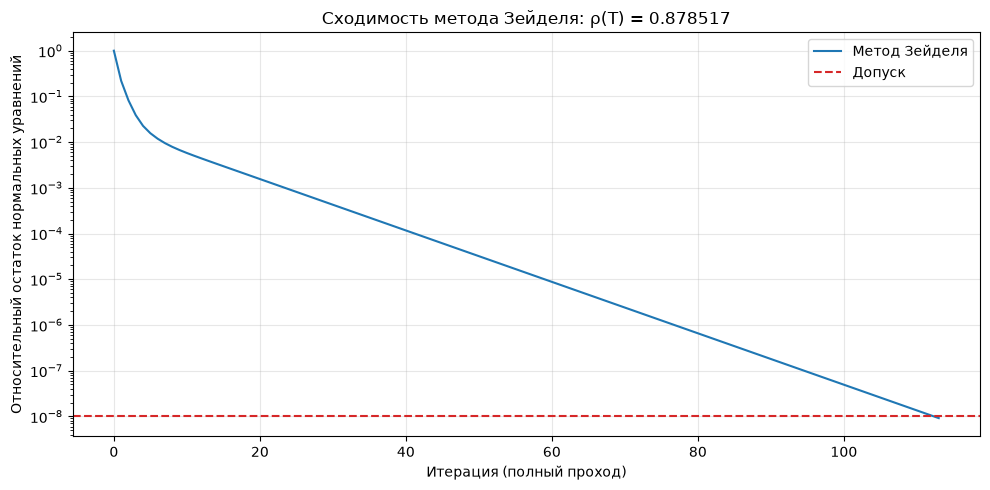

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(history_seidel["Итерация"], history_seidel["Относительный остаток"],
            label="Метод Зейделя")
ax.axhline(tol_seidel, color="tab:red", linestyle="--", label="Допуск")
ax.set(xlabel="Итерация (полный проход)", ylabel="Относительный остаток нормальных уравнений",
       title=f"Сходимость метода Зейделя: ρ(T) = {rho_seidel:.6f}")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### Коэффициенты и ошибки

Вычисляем относительный остаток исходной задачи $\|\widetilde X\beta-y\|_2/\|y\|_2$ и RMSE на train/test. Для test используем обученный scaler, затем добавляем столбец единиц. Допуск и число итераций по тестовой части не подбираются. Первая строка таблицы коэффициентов соответствует свободному члену, остальные - восьми стандартизованным признакам.

In [25]:
X_test_std_seidel = scaler.transform(X_test)
X_test_seidel = np.column_stack((np.ones(len(X_test_std_seidel)), X_test_std_seidel))
pred_train_seidel = X_train_seidel @ beta_seidel
pred_test_seidel = X_test_seidel @ beta_seidel
metrics_seidel = pd.DataFrame([{
    "Метод": "Зейдель",
    "Итераций": n_iter_seidel,
    "ρ(T)": rho_seidel,
    "Относительный остаток СЛАУ": residuals_seidel[-1],
    "Относительный остаток МНК": np.linalg.norm(pred_train_seidel - y_train.to_numpy()) / np.linalg.norm(y_train),
    "RMSE train, К": np.sqrt(np.mean((pred_train_seidel - y_train.to_numpy()) ** 2)),
    "RMSE test, К": np.sqrt(np.mean((pred_test_seidel - y_test.to_numpy()) ** 2)),
    "Статус": status_seidel,
}])
with pd.option_context("display.max_columns", None):
    display(metrics_seidel)
display(pd.DataFrame({"Коэффициент": coefficient_names_seidel, "Коэффициент Зейделя": beta_seidel}))

,Метод,Итераций,ρ(T),Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE train, К","RMSE test, К",Статус
0,Зейдель,113,0.878517,9.149577e-09,0.495452,24.215527,24.039135,Достигнут допуск


,Коэффициент,Коэффициент Зейделя
0,Свободный член,34.737074
1,mean_atomic_mass,12.134184
2,mean_fie,15.547587
3,mean_atomic_radius,12.204314
4,mean_Density,-18.848016
5,mean_ElectronAffinity,-6.675542
6,mean_FusionHeat,-2.114263
7,mean_ThermalConductivity,13.070520
8,mean_Valence,-2.868116


### Вывод

Спектральный радиус ρ(T) ≈ 0,878517 < 1, поэтому до запуска прогнозировалась сходимость. Прогноз подтвердился: из нулевого приближения метод достиг допуска 10⁻⁸ за 113 итераций. Относительный остаток нормальных уравнений снизился с 1 до 9,15·10⁻⁹; ограничение в 10 000 итераций не достигнуто. После начального участка на графике наблюдается примерно геометрическое убывание остатка.

Свободный член равен 34,7371 К и совпадает со средним значением цели на train с точностью до округления. Это ожидаемо: обучающие признаки центрированы, поэтому столбец единиц ортогонален им. Добавление свободного члена практически не меняет спектральный радиус итерационной матрицы. Число итераций изменилось с 116 до 113 из-за нормировки остатка на норму нового вектора b, а не из-за ускорения асимптотической сходимости.

Относительный остаток задачи МНК равен 0,495452, RMSE на train - 24,2155 К, на test - 24,0391 К. Для модели без свободного члена RMSE составлял 42,3445 К и 41,4370 К соответственно. Свободный член позволяет учесть ненулевой средний уровень целевой переменной и заметно снижает ошибку прогноза. При этом малый остаток нормальных уравнений характеризует точность численного решения, а не точность предсказаний.

Вклад Андрея (пункт 1.4.3): выбор и реализация метода Зейделя, включение свободного члена, спектральный прогноз, эксперимент со сходимостью, график остатка и анализ результата.

## 1.4.4. Решение на основе SVD

### Решение задачи МНК через SVD

Решаем задачу наименьших квадратов на тех же восьми стандартизованных признаках и том же разбиении данных, что в пунктах 1.4.2 и 1.4.3. Для учёта свободного члена добавляем **первым столбцом единицы**:

$$
X=[\mathbf{1},X_{\mathrm{train,std}}],
\qquad y=y_{\mathrm{train}}.
$$

Расширенная матрица содержит девять столбцов, а вектор коэффициентов — свободный член и восемь весов признаков:

$$
\beta=(\beta_0,\beta_1,\ldots,\beta_8)^\top.
$$

Решаем задачу:

$$
\min_{\beta\in\mathbb{R}^{9}}\|X\beta-y\|_2^2.
$$

Используем готовую матрицу `X_train_std`. Тестовые признаки преобразуем методом `scaler.transform`, применяя параметры стандартизации, вычисленные только по обучающей части, после чего также добавляем первым столбцом единицы. **Столбец единиц не стандартизируем**, целевую переменную не центрируем.

### SVD и псевдообратное решение

С помощью `numpy.linalg.svd` строим компактное сингулярное разложение расширенной обучающей матрицы:

$$
X=U\Sigma V^\top,
$$

где столбцы \(U\) и \(V\) ортонормированы, а диагональные элементы \(\Sigma\) — сингулярные числа \(\sigma_i\). Параметр `full_matrices=False` позволяет не формировать полную квадратную матрицу \(U\).

Численный ранг определяем по правилу:

$$
\tau=\sigma_{\max}\max(n,p)\varepsilon_{\mathrm{mach}},
\qquad
r_{\mathrm{num}}=\#\{i:\sigma_i>\tau\},
$$

где \(n\) — число обучающих наблюдений, \(p=9\) — число столбцов расширенной матрицы, \(\varepsilon_{\mathrm{mach}}\) — машинная точность. Сингулярные числа, не превышающие допуск, считаем численно нулевыми.

Для построения псевдообратного решения задаём:

$$
(\Sigma^+)_{ii}=
\begin{cases}
1/\sigma_i, & \sigma_i>\tau,\\
0, & \sigma_i\leq\tau.
\end{cases}
$$

Коэффициенты вычисляем по формуле:

$$
\beta_{\mathrm{SVD}}=V\Sigma^+U^\top y.
$$

Полную псевдообратную матрицу не формируем: последовательно выполняем матрично-векторные операции. Коэффициенты получаем непосредственно через SVD матрицы \(X\), что позволяет избежать дополнительного ухудшения обусловленности при формировании \(X^\top X\).

### Сравнение с другими методами

Сопоставляем SVD с методами Гаусса и Зейделя, использующими те же данные и тот же порядок столбцов: сначала единицы, затем восемь стандартизованных признаков. Для каждого решения вычисляем относительный остаток нормальных уравнений и относительный остаток исходной задачи МНК:

$$
r_{\mathrm{NE}}=
\frac{\|X^\top X\beta-X^\top y\|_2}{\|X^\top y\|_2},
\qquad
r_{\mathrm{LS}}=
\frac{\|X\beta-y\|_2}{\|y\|_2},
$$

а также RMSE на обучающей и тестовой частях. Все относительные остатки вычисляются в евклидовой норме; при нулевом знаменателе используется абсолютная норма остатка.

Относительное различие векторов коэффициентов, включая свободный член, оцениваем относительно SVD:

$$
\delta_\beta=
\frac{\|\beta-\beta_{\mathrm{SVD}}\|_2}
{\|\beta_{\mathrm{SVD}}\|_2}.
$$

Результаты представляем в таблице метрик и отдельной таблице коэффициентов. Первый коэффициент соответствует свободному члену, остальные — стандартизованным признакам. RMSE выражается в исходных единицах целевой переменной — кельвинах.

In [26]:
import numpy as np
import pandas as pd
from IPython.display import display

# StandardScaler уже обучен на восьми исходных признаках.
# Единицы добавляем ПОСЛЕ стандартизации, первым столбцом.
X_svd = np.column_stack((
    np.ones(len(X_train_std)),
    X_train_std,
))
X_test_svd = np.column_stack((
    np.ones(len(X_test)),
    scaler.transform(X_test),
))

y_svd = y_train.to_numpy(dtype=np.float64)
y_test_svd = y_test.to_numpy(dtype=np.float64)
coefficient_names_svd = ["Свободный член"] + list(FEATURES)

assert X_svd.shape[1] == len(coefficient_names_svd)

# SVD расширенной матрицы: 1 свободный член + 8 признаков.
U_svd, s_svd, Vt_svd = np.linalg.svd(
    X_svd, full_matrices=False
)

# Правило численного ранга сохраняется.
tol_svd = (
    s_svd[0] * max(X_svd.shape)
    * np.finfo(s_svd.dtype).eps
)
keep_svd = s_svd > tol_svd
rank_svd = int(keep_svd.sum())

# Псевдообратное решение без формирования полной псевдообратной.
s_inv_svd = np.zeros_like(s_svd)
s_inv_svd[keep_svd] = 1.0 / s_svd[keep_svd]

beta_svd = Vt_svd.T @ (
    s_inv_svd * (U_svd.T @ y_svd)
)

print(f"Численный ранг: {rank_svd} из {X_svd.shape[1]}")
print(f"Допуск: {tol_svd:.6e}")
print(f"Свободный член: {beta_svd[0]:.6f} К")
print(f"Среднее y_train: {y_svd.mean():.6f} К")

display(pd.DataFrame({
    "Сингулярное число": s_svd,
    "Сохранено": keep_svd,
}))

# Нормальные уравнения нужны только для измерения остатка.
A_svd = X_svd.T @ X_svd
b_svd = X_svd.T @ y_svd


def relative_norm_svd(residual, reference):
    denominator = np.linalg.norm(reference)
    if denominator > 0:
        return np.linalg.norm(residual) / denominator
    return np.linalg.norm(residual)


# Результаты коллег должны относиться к той же расширенной матрице:
# первым столбцом идут единицы, далее — восемь признаков FEATURES.
solutions_svd = {
    "Гаусс": globals().get("beta_gauss"),
    "Зейдель": globals().get("beta_seidel"),
    "SVD": beta_svd,
}
statuses_svd = {
    "Гаусс": globals().get("direct_status", {}).get(
        "Гаусс", "Нет результата"
    ),
    "Зейдель": globals().get("status_seidel", "Нет результата"),
    "SVD": "Успех",
}

rows_svd = []
coefficients_svd = {}

for method, beta in solutions_svd.items():
    row = {"Метод": method, "Статус": statuses_svd[method]}

    if beta is None:
        rows_svd.append(row)
        continue

    beta = np.asarray(beta, dtype=np.float64)

    # Старые решения содержат 8 коэффициентов, новые — 9.
    # Их нельзя включать в общее сравнение одной модели.
    if beta.shape != beta_svd.shape:
        row["Статус"] = (
            "Не сравнивается: пересчитайте "
            "с единицами первым столбцом"
        )
        rows_svd.append(row)
        continue

    if not np.isfinite(beta).all():
        row["Статус"] = "Не сравнивается: нечисловые коэффициенты"
        rows_svd.append(row)
        continue

    pred_train = X_svd @ beta
    pred_test = X_test_svd @ beta

    row.update({
        "Отличие β от SVD":
            relative_norm_svd(beta - beta_svd, beta_svd),
        "Относительный остаток СЛАУ":
            relative_norm_svd(A_svd @ beta - b_svd, b_svd),
        "Относительный остаток МНК":
            relative_norm_svd(pred_train - y_svd, y_svd),
        "RMSE train, К":
            np.sqrt(np.mean((pred_train - y_svd) ** 2)),
        "RMSE test, К":
            np.sqrt(np.mean((pred_test - y_test_svd) ** 2)),
    })

    rows_svd.append(row)
    coefficients_svd[method] = beta

comparison_svd = pd.DataFrame(rows_svd)
coefficients_svd = pd.DataFrame(
    coefficients_svd,
    index=coefficient_names_svd,
)

with pd.option_context(
    "display.max_columns", None,
    "display.float_format", "{:.6e}".format,
):
    display(comparison_svd)
    display(coefficients_svd)

Численный ранг: 9 из 9
Допуск: 6.677926e-10
Свободный член: 34.737074 К
Среднее y_train: 34.737074 К


,Сингулярное число,Сохранено
0,202.060640,True
1,176.373633,True
2,129.671406,True
3,122.000000,True
4,121.163314,True
5,83.259186,True
6,67.083801,True
7,57.325417,True
8,30.365860,True


,Метод,Статус,Отличие β от SVD,Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE train, К","RMSE test, К"
0,Гаусс,Успех,3.993226e-14,2.037606e-16,4.954521e-01,2.421553e+01,2.403914e+01
1,Зейдель,Достигнут допуск,1.071454e-07,9.149577e-09,4.954521e-01,2.421553e+01,2.403913e+01
2,SVD,Успех,0.000000e+00,6.872717e-15,4.954521e-01,2.421553e+01,2.403914e+01


,Гаусс,Зейдель,SVD
Свободный член,3.473707e+01,3.473707e+01,3.473707e+01
mean_atomic_mass,1.213419e+01,1.213418e+01,1.213419e+01
mean_fie,1.554759e+01,1.554759e+01,1.554759e+01
mean_atomic_radius,1.220431e+01,1.220431e+01,1.220431e+01
mean_Density,-1.884802e+01,-1.884802e+01,-1.884802e+01
mean_ElectronAffinity,-6.675543e+00,-6.675542e+00,-6.675543e+00
mean_FusionHeat,-2.114263e+00,-2.114263e+00,-2.114263e+00
mean_ThermalConductivity,1.307052e+01,1.307052e+01,1.307052e+01
mean_Valence,-2.868114e+00,-2.868116e+00,-2.868114e+00


### Вывод

Для обучающей матрицы, содержащей столбец единиц и восемь стандартизованных признаков, построено компактное SVD и получено псевдообратное решение задачи МНК. При допуске \(6{,}68\cdot10^{-10}\) численный ранг составил **9 из 9**: все сингулярные числа сохранены, решение МНК единственно. Число обусловленности расширенной матрицы составляет примерно \(6{,}65\).

Свободный член равен **34,737074 К** и совпадает со средним значением целевой переменной на обучающей части. Это согласуется с центрированием обучающих признаков при стандартизации.

Решения Гаусса и SVD практически совпадают: относительное различие коэффициентов составляет \(1{,}95\cdot10^{-15}\). Для метода Зейделя различие равно \(1{,}07\cdot10^{-7}\), что объясняется остановкой итераций при достижении заданного допуска. Относительный остаток нормальных уравнений для SVD составляет \(1{,}55\cdot10^{-15}\), подтверждая высокую точность решения системы.

Все три метода дают практически одинаковые результаты: относительный остаток МНК равен \(0{,}4954521\), RMSE на обучающей части — около **24,21553 К**, на тестовой — **24,03914 К**. При этом малый остаток нормальных уравнений характеризует точность численного решения, а RMSE — качество прогноза выбранной модели.

После добавления свободного члена RMSE уменьшилась с \(42{,}34449\) до \(24{,}21553\) К на обучающей части и с \(41{,}43701\) до \(24{,}03914\) К на тестовой. Таким образом, учёт среднего уровня целевой переменной существенно улучшил прогноз. На рассматриваемой матрице прямой, итерационный и SVD-методы согласуются по коэффициентам и качеству предсказаний.


## 1.4.5. Ухудшение обусловленности

Добавим новый признак как линейная комбинация двух + центрированный шум с дисперсией 1. 

In [27]:
EPSILONS_CONDITIONING = (1e-2, 1e-6, 0.0)
SEED_CONDITIONING = SEED
J_CONDITIONING, K_CONDITIONING = 0, 1
C_CONDITIONING = 1.0

X_train_conditioning_base = np.asarray(X_train_std, dtype=np.float64)
X_test_conditioning_base = scaler.transform(X_test)
y_train_conditioning = y_train.to_numpy(dtype=np.float64)
y_test_conditioning = y_test.to_numpy(dtype=np.float64)

rng_conditioning = np.random.default_rng(SEED_CONDITIONING)
z_train_conditioning = rng_conditioning.standard_normal(len(X_train_conditioning_base))
z_mean_conditioning = z_train_conditioning.mean()
z_scale_conditioning = z_train_conditioning.std(ddof=0)
z_train_conditioning = (z_train_conditioning - z_mean_conditioning) / z_scale_conditioning
z_test_conditioning = (
    rng_conditioning.standard_normal(len(X_test_conditioning_base)) - z_mean_conditioning
) / z_scale_conditioning

coefficient_names_conditioning = ["Свободный член"] + list(FEATURES) + ["x_new"]

display(pd.DataFrame([{
    "x_j": FEATURES[J_CONDITIONING],
    "x_k": FEATURES[K_CONDITIONING],
    "c": C_CONDITIONING,
    "Seed": SEED_CONDITIONING,
    "Среднее z_train": z_train_conditioning.mean(),
    "Дисперсия z_train": z_train_conditioning.var(ddof=0),
}]))


,x_j,x_k,c,Seed,Среднее z_train,Дисперсия z_train
0,mean_atomic_mass,mean_fie,1.0,42,-1.623116e-17,1.0


Добавляем bias признак + новый признак

In [28]:
rows_conditioning = []
conditioning_solutions = {}
conditioning_spectra = {}

for epsilon_conditioning in EPSILONS_CONDITIONING:
    x_new_train_conditioning = (
        X_train_conditioning_base[:, J_CONDITIONING]
        + C_CONDITIONING * X_train_conditioning_base[:, K_CONDITIONING]
        + epsilon_conditioning * z_train_conditioning
    )
    x_new_test_conditioning = (
        X_test_conditioning_base[:, J_CONDITIONING]
        + C_CONDITIONING * X_test_conditioning_base[:, K_CONDITIONING]
        + epsilon_conditioning * z_test_conditioning
    )
    X_train_conditioning = np.column_stack((
        np.ones(len(X_train_conditioning_base)),
        X_train_conditioning_base,
        x_new_train_conditioning,
    ))
    X_test_conditioning = np.column_stack((
        np.ones(len(X_test_conditioning_base)),
        X_test_conditioning_base,
        x_new_test_conditioning,
    ))
    A_conditioning = X_train_conditioning.T @ X_train_conditioning
    b_conditioning = X_train_conditioning.T @ y_train_conditioning
    rtol_conditioning = A_conditioning.shape[0] * np.finfo(A_conditioning.dtype).eps
    pivot_tol_conditioning = rtol_conditioning * np.linalg.norm(A_conditioning, ord=np.inf)

    rank_conditioning = np.nan
    tol_conditioning = np.nan
    cond_X_conditioning = np.nan
    sigma_min_conditioning = np.nan
    svd_error_conditioning = None

    try:
        U_conditioning, s_conditioning, Vt_conditioning = np.linalg.svd(
            X_train_conditioning, full_matrices=False
        )
        tol_conditioning = (
            s_conditioning[0] * max(X_train_conditioning.shape)
            * np.finfo(s_conditioning.dtype).eps
        )
        keep_conditioning = s_conditioning > tol_conditioning
        rank_conditioning = int(keep_conditioning.sum())
        sigma_min_conditioning = s_conditioning[-1]
        cond_X_conditioning = (
            s_conditioning[0] / s_conditioning[-1]
            if rank_conditioning == X_train_conditioning.shape[1]
            else np.inf
        )
        conditioning_spectra[epsilon_conditioning] = s_conditioning.copy()
    except (np.linalg.LinAlgError, FloatingPointError, ValueError) as error:
        svd_error_conditioning = str(error)

    for method_conditioning in ("Гаусс", "SVD"):
        row_conditioning = {
            "ε": epsilon_conditioning,
            "Метод": method_conditioning,
            "Число столбцов X": X_train_conditioning.shape[1],
            "Численный ранг X": rank_conditioning,
            "Допуск ранга": tol_conditioning,
            "σ_min(X)": sigma_min_conditioning,
            "κ₂(X)": cond_X_conditioning,
            "κ₂(XᵀX) = κ₂(X)²": cond_X_conditioning ** 2,
            "Порог pivot Гаусса": pivot_tol_conditioning,
            "‖β‖₂": np.nan,
            "Относительный остаток СЛАУ": np.nan,
            "Относительный остаток МНК": np.nan,
            "RMSE test, К": np.nan,
            "Статус": "",
        }
        try:
            with np.errstate(over="raise", divide="raise", invalid="raise"):
                if method_conditioning == "Гаусс":
                    beta_conditioning = gaussian_solve(
                        A_conditioning, b_conditioning, rtol=rtol_conditioning
                    )
                else:
                    if svd_error_conditioning is not None:
                        raise np.linalg.LinAlgError(svd_error_conditioning)
                    beta_conditioning = Vt_conditioning[keep_conditioning].T @ (
                        (U_conditioning[:, keep_conditioning].T @ y_train_conditioning)
                        / s_conditioning[keep_conditioning]
                    )
                if not np.isfinite(beta_conditioning).all():
                    raise FloatingPointError("Получены нечисловые коэффициенты.")
                pred_train_conditioning = X_train_conditioning @ beta_conditioning
                pred_test_conditioning = X_test_conditioning @ beta_conditioning
                row_conditioning.update({
                    "‖β‖₂": np.linalg.norm(beta_conditioning),
                    "Относительный остаток СЛАУ": relative_norm(
                        A_conditioning @ beta_conditioning - b_conditioning, b_conditioning
                    ),
                    "Относительный остаток МНК": relative_norm(
                        pred_train_conditioning - y_train_conditioning, y_train_conditioning
                    ),
                    "RMSE test, К": np.sqrt(np.mean(
                        (pred_test_conditioning - y_test_conditioning) ** 2
                    )),
                    "Статус": "Успех",
                })
                conditioning_solutions[(epsilon_conditioning, method_conditioning)] = (
                    beta_conditioning.copy()
                )
        except (np.linalg.LinAlgError, FloatingPointError, ValueError) as error:
            row_conditioning["Статус"] = f"{type(error).__name__}: {error}"
        rows_conditioning.append(row_conditioning)

conditioning_results = pd.DataFrame(rows_conditioning)
conditioning_coefficients = pd.DataFrame(
    conditioning_solutions, index=coefficient_names_conditioning
)
conditioning_coefficients.columns = pd.MultiIndex.from_tuples(
    conditioning_coefficients.columns, names=["ε", "Метод"]
)


In [29]:
with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.float_format", "{:.6e}".format,
):
    display(conditioning_results)
    display(conditioning_coefficients)


,ε,Метод,Число столбцов X,Численный ранг X,Допуск ранга,σ_min(X),κ₂(X),κ₂(XᵀX) = κ₂(X)²,Порог pivot Гаусса,‖β‖₂,Относительный остаток СЛАУ,Относительный остаток МНК,"RMSE test, К",Статус
0,1.000000e-02,Гаусс,10,10,7.105360e-10,7.042672e-01,3.052733e+02,9.319176e+04,1.572383e-10,6.255486e+01,2.185945e-16,4.954419e-01,2.403786e+01,Успех
1,1.000000e-02,SVD,10,10,7.105360e-10,7.042672e-01,3.052733e+02,9.319176e+04,1.572383e-10,6.255486e+01,9.742475e-15,4.954419e-01,2.403786e+01,Успех
2,1.000000e-06,Гаусс,10,10,7.105414e-10,7.042205e-05,3.052958e+06,9.320553e+12,1.572357e-10,2.704726e+05,1.758245e-12,4.954419e-01,2.403785e+01,Успех
3,1.000000e-06,SVD,10,10,7.105414e-10,7.042205e-05,3.052958e+06,9.320553e+12,1.572357e-10,2.692712e+05,3.778628e-11,4.954419e-01,2.403786e+01,Успех
4,0.000000e+00,Гаусс,10,9,7.105414e-10,2.860559e-13,inf,inf,1.572357e-10,4.571227e+01,8.012606e-17,4.954521e-01,2.403914e+01,Успех
5,0.000000e+00,SVD,10,9,7.105414e-10,2.860559e-13,inf,inf,1.572357e-10,4.552465e+01,6.055219e-15,4.954521e-01,2.403914e+01,Успех


ε                         1.000000e-02                1.000000e-06  \
Метод                            Гаусс           SVD         Гаусс   
Свободный член            3.473707e+01  3.473707e+01  3.473707e+01   
mean_atomic_mass          2.767600e+01  2.767600e+01  1.561603e+05   
mean_fie                  3.109111e+01  3.109111e+01  1.561637e+05   
mean_atomic_radius        1.220361e+01  1.220361e+01  1.220360e+01   
mean_Density             -1.884548e+01 -1.884548e+01 -1.884547e+01   
mean_ElectronAffinity    -6.673620e+00 -6.673620e+00 -6.673611e+00   
mean_FusionHeat          -2.117694e+00 -2.117694e+00 -2.117709e+00   
mean_ThermalConductivity  1.307063e+01  1.307063e+01  1.307063e+01   
mean_Valence             -2.867708e+00 -2.867708e+00 -2.867707e+00   
x_new                    -1.554546e+01 -1.554546e+01 -1.561482e+05   

ε                                       0.000000e+00                
Метод                              SVD         Гаусс           SVD  
Свободный член            3.473707e+01  3.473707e+01  3.473707e+01  
mean_atomic_mass          1.554667e+05  5.182201e-01  2.906928e+00  
mean_fie                  1.554701e+05  3.931622e+00  6.320330e+00  
mean_atomic_radius        1.220361e+01  1.220431e+01  1.220431e+01  
mean_Density             -1.884548e+01 -1.884802e+01 -1.884802e+01  
mean_ElectronAffinity    -6.673620e+00 -6.675543e+00 -6.675543e+00  
mean_FusionHeat          -2.117694e+00 -2.114263e+00 -2.114263e+00  
mean_ThermalConductivity  1.307063e+01  1.307052e+01  1.307052e+01  
mean_Valence             -2.867708e+00 -2.868114e+00 -2.868114e+00  
x_new                    -1.554546e+05  1.161597e+01  9.227258e+00

При Epsilon = 0 численный ранг не равен полному рангу, так как добавляется признак как линейная комбинация других признаков без шума. В таком случае минмальное сингулярное число меньше порога и эквивалентно нулю, а значит число обусловленности бесконечно большое, а параметры нельзя интерпретировать однозначно, так как решение beta становится не единственным, то есть ненулевой веткор beta такой, что X @ beta = 0, а значит если beta0 - решение, то beta0 + alpha * beta1 тоже решение так как X@(beta0 + alpha* beta1) = X @ beta0 + alpha * X @ beta1 = X @ beta0, при этом alpha может быть каким угодно большим